# StereoMIS ablation study
Compute the dataset-level mean using **only the four `p*_s4` sequences**, then plot PSNR, SSIM, and LPIPS for `alpha_3d` and `flow_loss_weight` in a 2 x 3 figure.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path = Path('tmp/mean_results_ablation.csv')
df = pd.read_csv(csv_path)
df.head()

,Method,Video,Config,PSNR,SSIM,LPIPS,Gaussians,PeakGPUMemoryMB,TrainingTimeSeconds
0,EndoFlow,cutting,alpha3d_0.0,39.229671,0.971798,0.030861,49098.0,2988.488037,322.755680
1,EndoFlow,cutting,alpha3d_0.1,39.348509,0.972391,0.029993,48947.0,2979.821045,320.713125
2,EndoFlow,cutting,alpha3d_0.2,39.350159,0.972480,0.029380,48776.5,2972.265137,317.716418
3,EndoFlow,cutting,alpha3d_0.25,39.335632,0.972444,0.029460,48711.0,2977.295410,315.166893
4,EndoFlow,cutting,alpha3d_0.3,39.299740,0.972296,0.029422,48702.0,2969.564697,311.567091


In [2]:
# Keep ONLY the four StereoMIS p*_s4 sequences.
stereomis = df[df['Video'].str.match(r'^p.*_s4$', na=False)].copy()
videos = sorted(stereomis['Video'].unique())
print(f'Number of selected videos: {len(videos)}')
print('Selected videos:')
for video in videos:
    print(' -', video)

assert len(videos) == 4, f'Expected 4 p*_s4 videos, found {len(videos)}'

Number of selected videos: 4
Selected videos:
 - p2_1_1_247_s4
 - p2_6_5000_200_s4
 - p3_11000_401_s4
 - p3_9100_368_s4


In [3]:
# Mean PSNR / SSIM / LPIPS across the four selected videos for every setting.
metrics = ['PSNR', 'SSIM', 'LPIPS']
mean_df = stereomis.groupby('Config', as_index=False)[metrics].mean()

alpha_df = mean_df[mean_df['Config'].str.startswith('alpha3d_')].copy()
alpha_df['Value'] = alpha_df['Config'].str.replace('alpha3d_', '', regex=False).astype(float)
alpha_df = alpha_df.sort_values('Value').reset_index(drop=True)

flow_df = mean_df[mean_df['Config'].str.startswith('flowloss_')].copy()
flow_df['Value'] = flow_df['Config'].str.replace('flowloss_', '', regex=False).astype(float)
flow_df = flow_df.sort_values('Value').reset_index(drop=True)

display(alpha_df[['Value', *metrics]])
display(flow_df[['Value', *metrics]])

,Value,PSNR,SSIM,LPIPS
0,0.00,30.344774,0.800724,0.171778
1,0.10,30.481861,0.806285,0.172237
2,0.20,30.526617,0.809027,0.172783
3,0.25,30.508454,0.808983,0.174003
4,0.30,30.492480,0.808496,0.174331
5,0.40,30.393311,0.806367,0.174913
6,0.50,30.275047,0.802829,0.175919


,Value,PSNR,SSIM,LPIPS
0,0.0000,30.391108,0.804426,0.173055
1,0.0001,30.448808,0.806448,0.171825
2,0.0005,30.493926,0.808674,0.172101
3,0.0010,30.508502,0.808925,0.173449
4,0.0050,30.508145,0.806802,0.180417
5,0.0100,30.472928,0.804292,0.184633
6,0.1000,30.206282,0.790807,0.201222
7,1.0000,30.004321,0.781362,0.210813


In [4]:
# Save the mean values.
alpha_out = alpha_df[['Value', *metrics]].copy()
alpha_out.insert(0, 'Ablation', 'alpha_3d')
flow_out = flow_df[['Value', *metrics]].copy()
flow_out.insert(0, 'Ablation', 'flow_loss_weight')
summary = pd.concat([alpha_out, flow_out], ignore_index=True)
summary.to_csv('stereomis_mean_ablation_p_s4.csv', index=False)
summary

,Ablation,Value,PSNR,SSIM,LPIPS
0,alpha_3d,0.0000,30.344774,0.800724,0.171778
1,alpha_3d,0.1000,30.481861,0.806285,0.172237
2,alpha_3d,0.2000,30.526617,0.809027,0.172783
3,alpha_3d,0.2500,30.508454,0.808983,0.174003
4,alpha_3d,0.3000,30.492480,0.808496,0.174331
5,alpha_3d,0.4000,30.393311,0.806367,0.174913
6,alpha_3d,0.5000,30.275047,0.802829,0.175919
7,flow_loss_weight,0.0000,30.391108,0.804426,0.173055
8,flow_loss_weight,0.0001,30.448808,0.806448,0.171825
9,flow_loss_weight,0.0005,30.493926,0.808674,0.172101


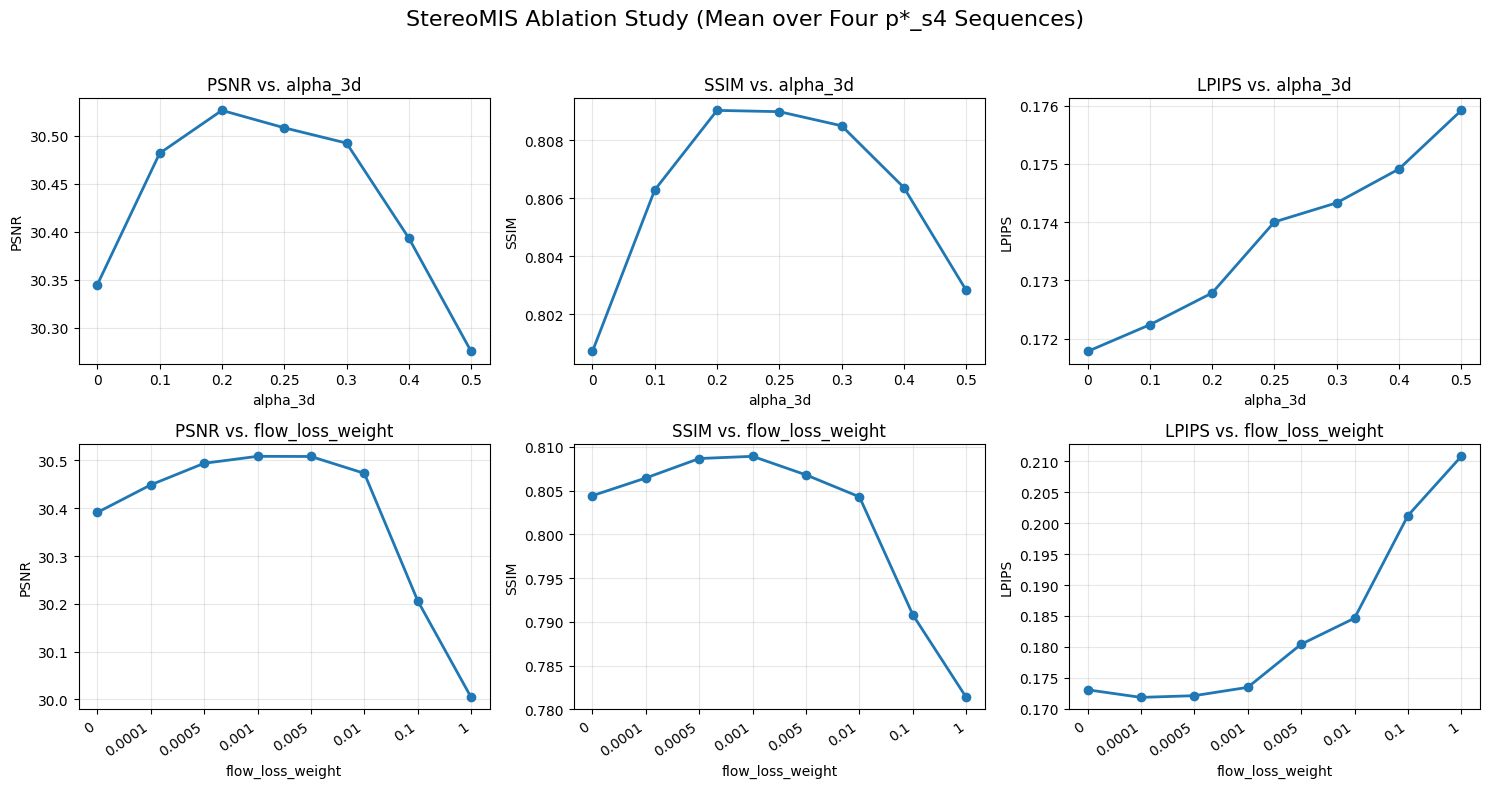

In [5]:
# 2 x 3 line charts:
# row 1 = alpha_3d, row 2 = flow_loss_weight
# columns = PSNR, SSIM, LPIPS
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, metric in enumerate(metrics):
    # alpha_3d
    x = np.arange(len(alpha_df))
    axes[0, col].plot(x, alpha_df[metric], marker='o', linewidth=2)
    axes[0, col].set_xticks(x)
    axes[0, col].set_xticklabels([f'{v:g}' for v in alpha_df['Value']])
    axes[0, col].set_xlabel('alpha_3d')
    axes[0, col].set_ylabel(metric)
    axes[0, col].set_title(f'{metric} vs. alpha_3d')
    axes[0, col].grid(True, alpha=0.3)

    # flow_loss_weight
    # Treat tested settings as ordered categories so tiny values are not compressed near zero.
    x = np.arange(len(flow_df))
    axes[1, col].plot(x, flow_df[metric], marker='o', linewidth=2)
    axes[1, col].set_xticks(x)
    axes[1, col].set_xticklabels([f'{v:g}' for v in flow_df['Value']], rotation=35, ha='right')
    axes[1, col].set_xlabel('flow_loss_weight')
    axes[1, col].set_ylabel(metric)
    axes[1, col].set_title(f'{metric} vs. flow_loss_weight')
    axes[1, col].grid(True, alpha=0.3)

fig.suptitle('StereoMIS Ablation Study (Mean over Four p*_s4 Sequences)', fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])

out_dir = Path('tmp/ablation_alpha')
out_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(out_dir / 'stereomis_ablation_2x3.pdf', bbox_inches='tight')
fig.savefig(out_dir / 'stereomis_ablation_2x3.png', dpi=220, bbox_inches='tight')
plt.show()